# Preparación de datos: ¿qué sirve para entrenar la detección de agua?

Este notebook es el **único que lee los datos crudos** de `Data/`. Evalúa cada evento de cada fuente, se queda solo con lo que sirve y deja todo preprocesado en `Data/procesado/preparado/`. `pipeline_inundaciones.ipynb` consume únicamente esa carpeta.

```
Data/ (crudo) ──► preparacion_datos.ipynb ──► Data/procesado/preparado/ ──► pipeline_inundaciones.ipynb
                                               ├─ calidad.csv            (¿sirve cada evento? y por qué)
                                               ├─ inventario.csv, indice.csv, particion.json, stats.json
                                               ├─ parches/  empaquetado/ (entrenamiento y validación)
                                               └─ pruebas/  bolivia.npz, lima_2017.npz, lima_2023.npz, distritos_lima.gpkg
```

**No se recorre el dataset completo.** La calidad se evalúa con una muestra al azar de `ITEMS_CALIDAD` items por evento, y el inventario de ventanas solo se hace sobre una muestra de los eventos que sirven, la justa para tener `VENTANAS_INVENTARIO` ventanas por evento (de las que salen `MAX_PARCHES_EVENTO` parches).

**Datos que se usan** (revisados a mano, ver sección 1):

| dato | uso |
|---|---|
| Kuro Siwo **Chad, Harvey, Yibuti** | entrenamiento; validación = bloques geográficos de 10 km de Harvey (~20 %), sin teselas vecinas entre train y val |
| Sen1Floods11 **Bolivia** (15 chips manuales) | prueba externa |
| Sentinel-1 **Lima** 2017 y 2023 + HAND, DEM, JRC | prueba y aplicación |
| **EMSN038** (2017) y **CONIDA** (2023) | referencias de Lima |

Se descartaron Sen1Floods11 Colombia (etiqueta = umbral Otsu sobre la propia imagen), UrbanSARFloods (polígonos gruesos: 0–0,3 % del agua en manchas < 1 ha, y ríos y mar sin etiquetar) y Kuro Siwo Madagascar (75–90 % del agua en ríos y cuerpos > 100 ha). Para Lima importan las **manchas chicas**: anegamientos de calles y lotes.

**Criterios** (en `src/config.py`, `CALIDAD`). Un evento sirve para el modo `agua` si:

1. marca como agua el **agua permanente** según JRC Global Surface Water;
2. el agua etiquetada **se ve como agua en radar** (VH < −18 dB en al menos la mitad de sus píxeles);
3. tiene suficientes ventanas válidas.

Para el modo `cambio` además necesita imagen previa y que la inundación etiquetada **se separe por ΔVH** (AUC ≥ 0,70). La tabla también muestra el **tamaño de las manchas** de agua de cada evento.


## 0. Entorno

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", message=".*Measured \\(M\\) geometry.*")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C, datos as D, entrenamiento as E, preparacion as P

C.PREPARADO.mkdir(parents=True, exist_ok=True)
REHACER = False   # True para recalcular todo aunque ya exista
print(f"datos crudos: {C.DATOS}\nsalida: {C.PREPARADO}")

datos crudos: C:\Ciclo09\MachineLearning\ProyectoMachineLearning\Data
salida: C:\Ciclo09\MachineLearning\ProyectoMachineLearning\Data\procesado\preparado


## 1. Fuentes
Un registro por archivo / tesela. Validación = bloques geográficos de `VAL_BLOQUE_KM` km de Harvey hasta cubrir `VAL_FRAC` de sus teselas; las teselas de entrenamiento que tocan una de validación se descartan.

In [2]:
items = D.listar_items()
items.groupby(["particion", "dataset", "evento"]).agg(items=("item", "size"), con_imagen_previa=("tiene_pre", "sum"))

items  con_imagen_previa
particion dataset  evento                          
train     kurosiwo chad       32                 32
                   harvey   3298               3298
                   yibuti     19                 19
val       kurosiwo harvey   1011               1011

### 1.1 Un ejemplo de cada dato, en su formato original
Para cada dato que se usa: qué archivos y bandas trae, en qué unidades (Kuro Siwo viene en potencia **lineal**, Bolivia y Lima en **dB**), resolución, CRS, rango de valores y el dibujo de cada capa. Kuro Siwo: una tesela de cada evento (Chad, Harvey en train, Harvey en validación, Yibuti).


=== kurosiwo chad (train): ec520bdd9db35187897fd43ab3b8d6fe


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV antes (lineal),SL1_IVV_1111002_01_20200705.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.003,0.035,1.889,
1,VH antes (lineal),SL1_IVH_1111002_01_20200705.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.000,0.003,0.089,
2,VV durante (lineal),MS1_IVV_1111002_01_20200915.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.004,0.122,3.599,
3,VH durante (lineal),MS1_IVH_1111002_01_20200915.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.001,0.021,0.157,
4,etiqueta (0/1 perm./2 inund./3 inválido),MK0_MLU_1111002_01_20200915.tif,1/1,224×224,uint8,10 m,EPSG:3857,3.0,0.000,0.000,2.000,"0, 2"
5,válido (MNA),MK0_MNA_1111002_01_20200915.tif,1/1,224×224,uint8,10 m,EPSG:3857,0.0,1.000,1.000,1.000,1


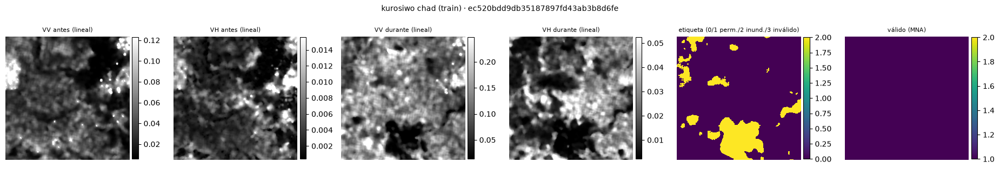


=== kurosiwo harvey (train): a56b18b78a905173ac085d77af3cedcf


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV antes (lineal),SL1_IVV_1111004_01_20170805.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.037,0.109,0.465,
1,VH antes (lineal),SL1_IVH_1111004_01_20170805.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.004,0.030,0.141,
2,VV durante (lineal),MS1_IVV_1111004_01_20170829.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.021,0.145,1.294,
3,VH durante (lineal),MS1_IVH_1111004_01_20170829.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.001,0.045,0.193,
4,etiqueta (0/1 perm./2 inund./3 inválido),MK0_MLU_1111004_01_20170829.tif,1/1,224×224,uint8,10 m,EPSG:3857,3.0,0.000,0.000,2.000,"0, 2"
5,válido (MNA),MK0_MNA_1111004_01_20170829.tif,1/1,224×224,uint8,10 m,EPSG:3857,0.0,1.000,1.000,1.000,1


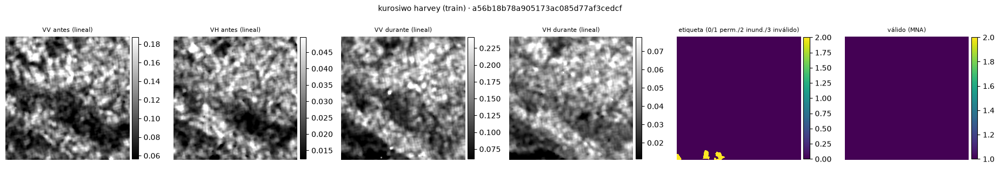


=== kurosiwo harvey (val): a331706c2ca15513b1a76f0a9cdce7d7


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV antes (lineal),SL1_IVV_1111004_01_20170805.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.003,0.088,1.665,
1,VH antes (lineal),SL1_IVH_1111004_01_20170805.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.000,0.028,0.199,
2,VV durante (lineal),MS1_IVV_1111004_01_20170829.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.008,0.089,6.419,
3,VH durante (lineal),MS1_IVH_1111004_01_20170829.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.000,0.027,0.557,
4,etiqueta (0/1 perm./2 inund./3 inválido),MK0_MLU_1111004_01_20170829.tif,1/1,224×224,uint8,10 m,EPSG:3857,3.0,0.000,0.000,2.000,"0, 1, 2"
5,válido (MNA),MK0_MNA_1111004_01_20170829.tif,1/1,224×224,uint8,10 m,EPSG:3857,0.0,1.000,1.000,1.000,1


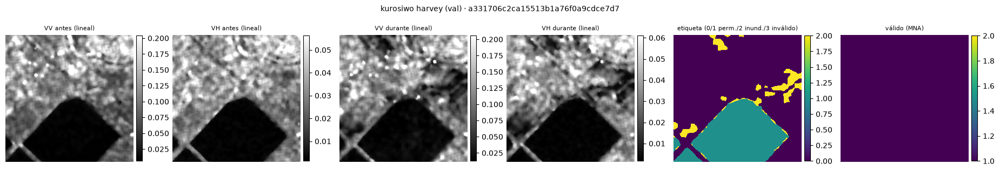


=== kurosiwo yibuti (train): 06da57ae6bf35b32b8f138c20512d767


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV antes (lineal),SL1_IVV_1111003_01_20191115.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.006,0.101,48.624001,
1,VH antes (lineal),SL1_IVH_1111003_01_20191115.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.000,0.013,0.959000,
2,VV durante (lineal),MS1_IVV_1111003_01_20191127.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.005,0.142,14.857000,
3,VH durante (lineal),MS1_IVH_1111003_01_20191127.tif,1/1,224×224,float32,10 m,EPSG:3857,0.0,0.000,0.018,0.726000,
4,etiqueta (0/1 perm./2 inund./3 inválido),MK0_MLU_1111003_01_20191127.tif,1/1,224×224,uint8,10 m,EPSG:3857,3.0,0.000,0.000,2.000000,"0, 2"
5,válido (MNA),MK0_MNA_1111003_01_20191127.tif,1/1,224×224,uint8,10 m,EPSG:3857,0.0,1.000,1.000,1.000000,1


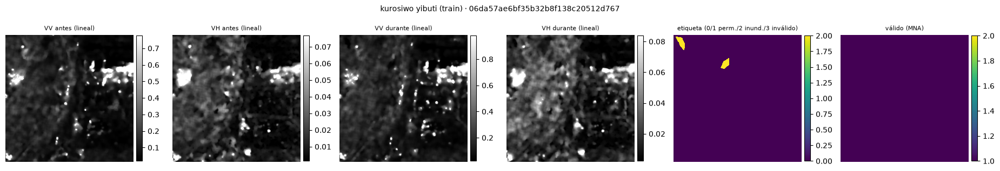


=== bolivia: Bolivia_103757_S1Hand.tif


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV (dB),Bolivia_103757_S1Hand.tif,1/2,512×512,float32,8.98e-05 °,EPSG:4326,NaN,-40.820999,-11.735000,-0.691,
1,VH (dB),Bolivia_103757_S1Hand.tif,2/2,512×512,float32,8.98e-05 °,EPSG:4326,NaN,-48.248001,-17.577999,-6.995,
2,etiqueta manual (-1/0/1),Bolivia_103757_LabelHand.tif,1/1,512×512,int16,8.98e-05 °,EPSG:4326,NaN,-1.000000,-1.000000,1.000,"-1, 0, 1"


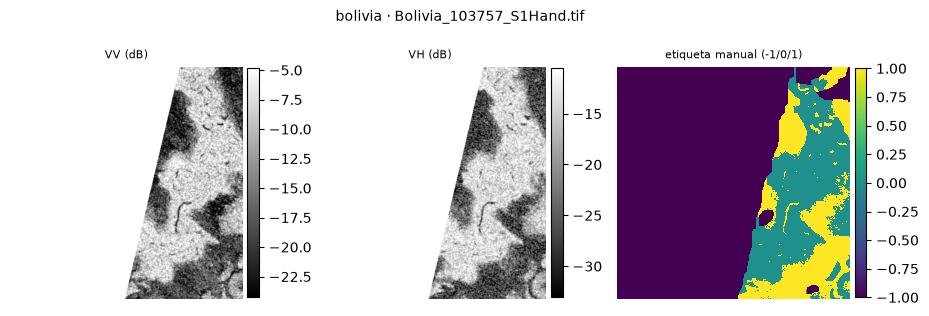

In [3]:
from IPython.display import display
ks = items[items.dataset == "kurosiwo"]
ejemplos_crudos = [(f"kurosiwo {ev} ({part})", "kurosiwo", g.sample(1, random_state=C.SEMILLA).item.iloc[0])
                   for (ev, part), g in ks.groupby(["evento", "particion"])]
ejemplos_crudos.append(("bolivia", "bolivia", str(sorted((C.BOLIVIA / "S1Hand").glob("*.tif"))[0])))
for nombre, ds, item in ejemplos_crudos:
    capas = P.capas_crudas(ds, item)
    print(f"\n=== {nombre}: {Path(item).name}")
    display(P.describir_capas(capas).round(3))
    P.mostrar_capas(capas, f"{nombre} · {Path(item).name}")

### 1.2 Kuro Siwo ya convertido: un ejemplo por evento
El item con más agua entre 10 al azar de cada evento, ya en dB: VH antes y durante, ΔVH, la etiqueta (0 sin agua, 1 permanente, 2 inundación, −1 inválido) y la ocurrencia de agua JRC.

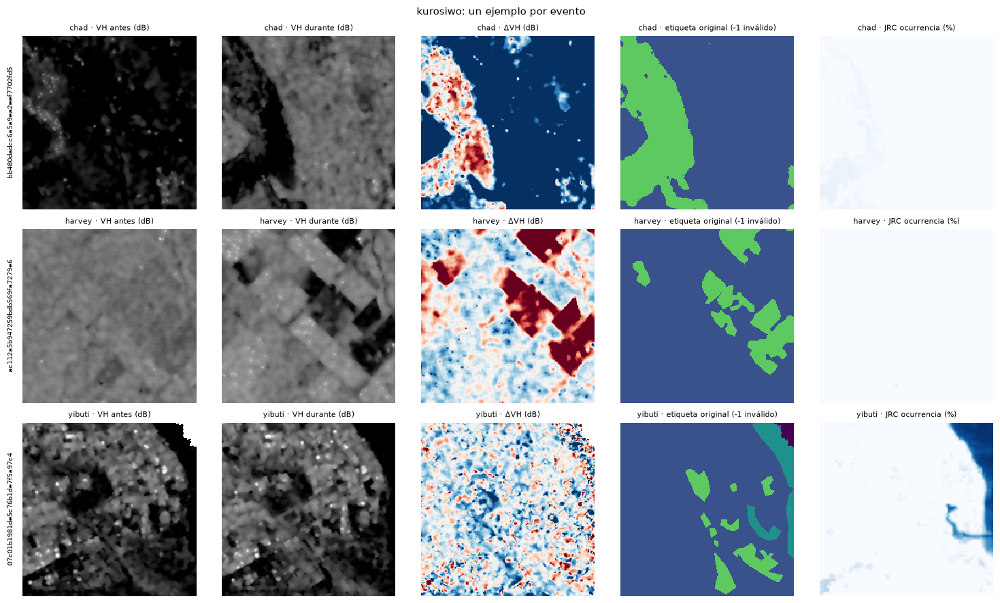

In [4]:
P.ejemplo_por_evento(items, "kurosiwo")

### 1.3 Escenas Sentinel-1 de Lima (las cuatro fechas)
Procesadas en SNAP con `scripts/grafo.xml` (σ⁰ en dB, Refined Lee, corrección de terreno, EPSG:32718 a 10 m).


=== lima_2017_0305


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV (dB),lima_2017_0305.tif,1/2,7302×7205,float32,10 m,EPSG:32718,None,-104.947998,-4.942,26.225000,
1,VH (dB),lima_2017_0305.tif,2/2,7302×7205,float32,10 m,EPSG:32718,None,-104.947998,-12.973,20.249001,


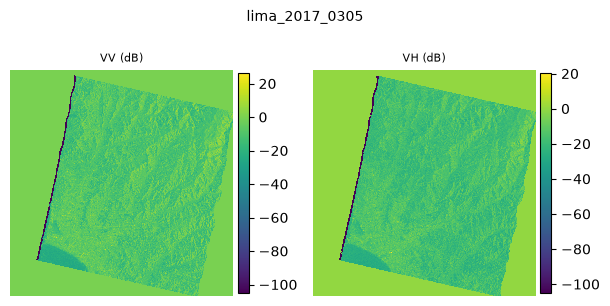


=== lima_2017_0317


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV (dB),lima_2017_0317.tif,1/2,7304×7213,float32,10 m,EPSG:32718,None,-104.947998,-4.682,21.895000,
1,VH (dB),lima_2017_0317.tif,2/2,7304×7213,float32,10 m,EPSG:32718,None,-104.947998,-12.828,16.436001,


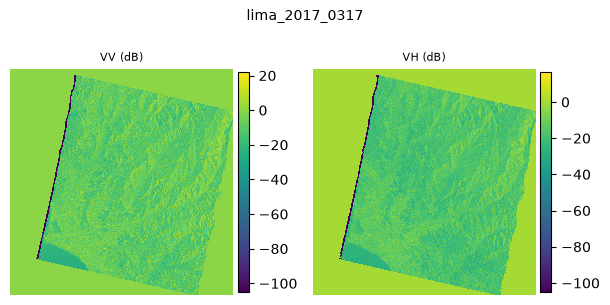


=== lima_2023_0304


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV (dB),lima_2023_0304.tif,1/2,5839×6070,float32,10 m,EPSG:32718,None,-105.098000,-8.821,25.723,
1,VH (dB),lima_2023_0304.tif,2/2,5839×6070,float32,10 m,EPSG:32718,None,-105.134003,-16.695,17.993,


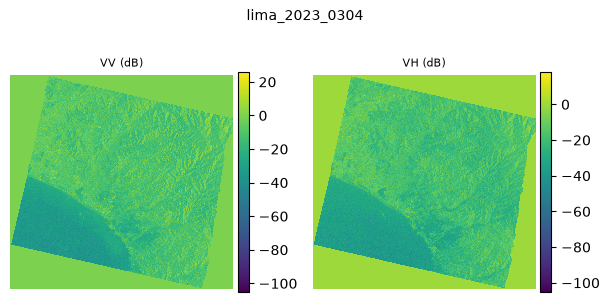


=== lima_2023_0316


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,VV (dB),lima_2023_0316.tif,1/2,5828×6064,float32,10 m,EPSG:32718,None,-105.082001,-7.956,28.910,
1,VH (dB),lima_2023_0316.tif,2/2,5828×6064,float32,10 m,EPSG:32718,None,-105.107002,-15.959,20.125,


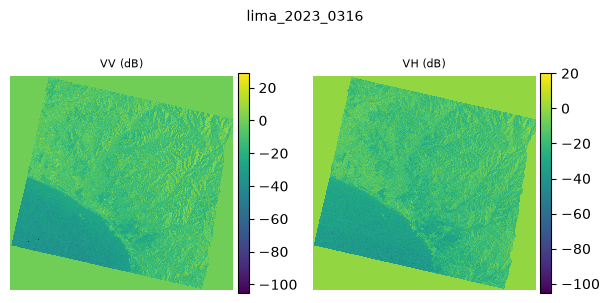

In [5]:
for escena in ["lima_2017_0305", "lima_2017_0317", "lima_2023_0304", "lima_2023_0316"]:
    capas = P.capas_crudas("lima", escena)
    print(f"\n=== {escena}")
    display(P.describir_capas(capas).round(3))
    P.mostrar_capas(capas, escena)

### 1.4 Referencias de Lima: EMSN038 (2017) y CONIDA (2023)

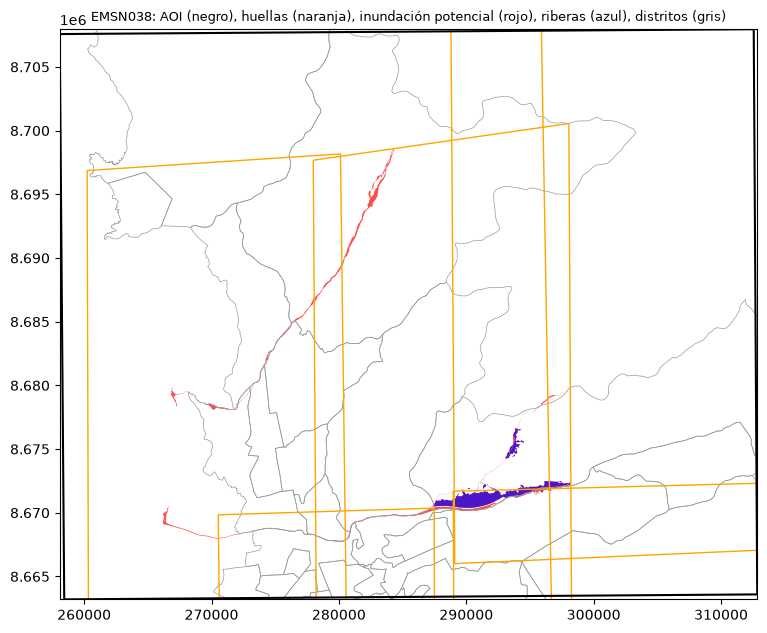

,capa,objetos,geometría,km²,columnas
0,EMSN038_AOI,1,MultiPolygon,2416.16,"Name, descriptio, timestamp, begin, end, altit..."
1,Footprints,6,MultiPolygon,4648.14,"SDV, SDP, SHAPE_Length, SHAPE_Area"
2,Potential_Maximum_flood,13,MultiPolygon,13.58,"ID, source, Shape_Length, Shape_Area"
3,Riverbank,11,MultiPolygon,7.24,"source, Shape_Length, Shape_Area"
4,Admin_MINAM_BAS_LIM_DISTRITOS,43,MultiPolygon,2699.74,"OBJECTID, IDDIST, IDDPTO, IDPROV, NOMBDIST, NO..."


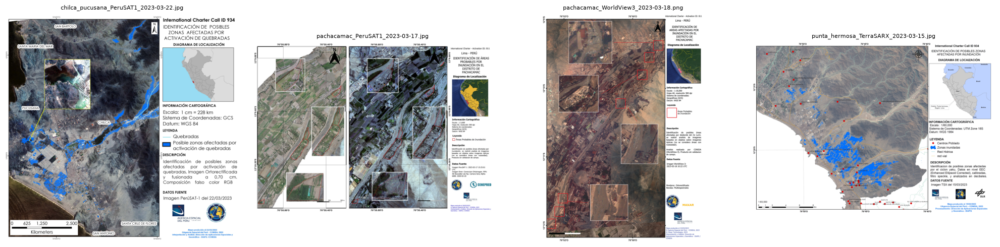

,archivo,tamaño,modo,MB
0,chilca_pucusana_PeruSAT1_2023-03-22.jpg,4232×4133,RGB,2.0
1,pachacamac_PeruSAT1_2023-03-17.jpg,2571×1816,RGB,2.0
2,pachacamac_WorldView3_2023-03-18.png,3639×5147,RGB,32.8
3,punta_hermosa_TerraSARX_2023-03-15.jpg,3858×2727,RGB,6.1


In [6]:
display(P.mostrar_emsn038())
display(P.mostrar_conida())

### 1.5 Capas auxiliares de Lima: HAND y DEM (Copernicus GLO-30)
HAND = altura sobre el drenaje más cercano (filtro de zonas altas); DEM para separar tierra firme del mar. La ocurrencia JRC de Lima se ve en la sección 4, ya en la grilla de las escenas.


=== HAND (m)


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,HAND (m) S12_00_W077_00,Copernicus_DSM_COG_10_S12_00_W077_00_HAND.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,0.0,70.550003,1325.619995,
1,HAND (m) S12_00_W078_00,Copernicus_DSM_COG_10_S12_00_W078_00_HAND.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,0.0,0.000000,991.190002,
2,HAND (m) S13_00_W077_00,Copernicus_DSM_COG_10_S13_00_W077_00_HAND.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,0.0,36.750000,1241.000000,
3,HAND (m) S13_00_W078_00,Copernicus_DSM_COG_10_S13_00_W078_00_HAND.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,0.0,0.000000,373.850006,


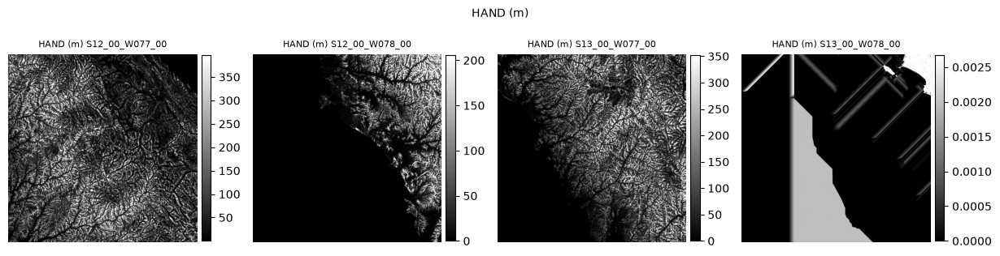


=== DEM (m)


,capa,archivo,banda,forma,tipo,resolución,crs,nodata,mín,p50,máx,valores
0,DEM (m) S12_00_W077_00,Copernicus_DSM_COG_10_S12_00_W077_00_DEM.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,217.479996,4250.240234,5667.450195,
1,DEM (m) S12_00_W078_00,Copernicus_DSM_COG_10_S12_00_W078_00_DEM.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,-8.640000,0.000000,3859.040039,
2,DEM (m) S13_00_W077_00,Copernicus_DSM_COG_10_S13_00_W077_00_DEM.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,-3.700000,1044.140015,5192.479980,
3,DEM (m) S13_00_W078_00,Copernicus_DSM_COG_10_S13_00_W078_00_DEM.tif,1/1,3600×3600,float32,0.000278 °,EPSG:4326,None,-0.040000,0.000000,651.099976,


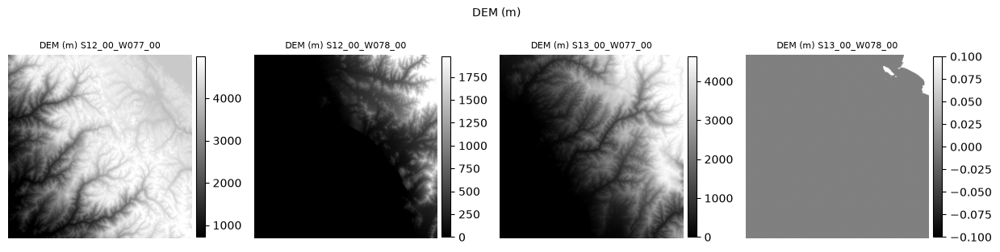

In [7]:
for nombre, rutas in [("HAND (m)", C.HAND), ("DEM (m)", C.DEM)]:
    capas = [(f"{nombre} {r.name.split('_10_')[1][:14]}", r, 1) for r in rutas]
    print(f"\n=== {nombre}")
    display(P.describir_capas(capas).round(2))
    P.mostrar_capas(capas, nombre)

## 2. Muestra para evaluar la calidad
Hasta `ITEMS_CALIDAD` items al azar por evento. Todo lo que sigue hasta la sección 5 trabaja sobre esta muestra.

In [8]:
muestra = P.muestra_calidad(items)
muestra.groupby(["dataset", "evento"]).size().rename("items_muestra").to_frame().join(
    items.groupby("evento").size().rename("items_total"), on="evento")

C:\Ciclo09\MachineLearning\ProyectoMachineLearning\src\preparacion.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), n), random_state=C.SEMILLA)).reset_index(drop=True))


items_muestra  items_total
dataset  evento                            
kurosiwo chad               32           32
         harvey             40         4309
         yibuti             19           19

## 3. Agua permanente de referencia (JRC Global Surface Water)
Solo las teselas de 10° donde caen los items de la muestra. Se usan para medir si cada fuente etiqueta el agua permanente.

In [9]:
def bajar_teselas(df):
    teselas = D.teselas_jrc_necesarias(df)
    faltan = [t for t in teselas if not (C.JRC_GLOBAL / f"occurrence_{t}v1_4_2021.tif").exists()]
    print(f"{len(teselas)} teselas JRC necesarias, faltan {len(faltan)}")
    P.descargar_jrc(faltan)

bajar_teselas(muestra)

3 teselas JRC necesarias, faltan 0


## 4. Datos de prueba ya alineados
* **Bolivia** (Sen1Floods11, 15 chips con etiqueta manual).
* **Lima 2017** y **Lima Sur 2023**: la imagen previa se reproyecta a la grilla de la imagen durante el evento, y se agregan HAND, DEM y ocurrencia JRC en la misma grilla. En 2017 se rasteriza además la referencia EMSN038.
* **Distritos** de la provincia de Lima.

In [10]:
from IPython.display import display
P.preparar_bolivia(REHACER)
P.preparar_lima(REHACER)
P.preparar_distritos(REHACER)
for r in sorted(C.PRUEBAS.glob("*.npz")):
    print(f"\n=== {r.name} ({r.stat().st_size / 1e6:.0f} MB)")
    display(P.describir_npz(r))


=== bolivia.npz (35 MB)


,variable,forma,tipo,MB,mín,máx,% NaN
0,nombres,15,<U14,0.0,,,
1,post,15×2×512×512,float32,31.5,-103.87603,8.278705,10.33
2,ref,15×512×512,int8,3.9,-1,1,



=== lima_2017.npz (1212 MB)


,variable,forma,tipo,MB,mín,máx,% NaN
0,post,2×7304×7213,float32,421.5,-104.947945,36.513588,0.0
1,pre,2×7304×7213,float32,421.5,-104.947906,36.086945,38.58
2,hand,7304×7213,float16,105.4,0.000000,971.000000,0.0
3,dem,7304×7213,float16,105.4,-6.238281,4664.000000,0.0
4,jrc,7304×7213,float16,105.4,0.000000,100.000000,0.0
5,ref,7304×7213,int8,52.7,-1.000000,1.000000,



=== lima_2023.npz (778 MB)


,variable,forma,tipo,MB,mín,máx,% NaN
0,post,2×5828×6064,float32,282.7,-105.148682,30.112043,0.00
1,pre,2×5828×6064,float32,282.7,-105.133667,28.835548,30.55
2,hand,5828×6064,float16,70.7,0.000000,810.500000,0.00
3,dem,5828×6064,float16,70.7,-4.078125,3670.000000,0.00
4,jrc,5828×6064,float16,70.7,0.000000,255.000000,0.00


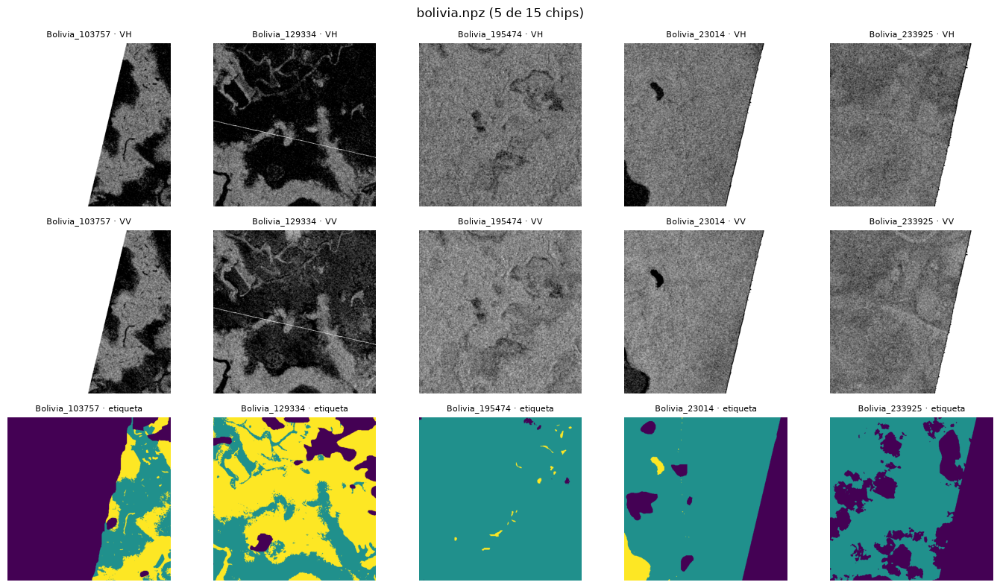

In [11]:
bol = np.load(C.PRUEBAS / "bolivia.npz")
fig, ejes = plt.subplots(3, 5, figsize=(14, 8))
for k, ax in enumerate(ejes.ravel()[:5]):
    ax.imshow(bol["post"][k, 1], cmap="gray", vmin=-25, vmax=0); ax.set_title(f"{bol['nombres'][k]} · VH", fontsize=8); ax.axis("off")
for k, ax in enumerate(ejes.ravel()[5:10]):
    ax.imshow(bol["post"][k, 0], cmap="gray", vmin=-20, vmax=5); ax.set_title(f"{bol['nombres'][k]} · VV", fontsize=8); ax.axis("off")
for k, ax in enumerate(ejes.ravel()[10:]):
    ax.imshow(bol["ref"][k], cmap="viridis", vmin=-1, vmax=1); ax.set_title(f"{bol['nombres'][k]} · etiqueta", fontsize=8); ax.axis("off")
plt.suptitle("bolivia.npz (5 de 15 chips)"); plt.tight_layout()

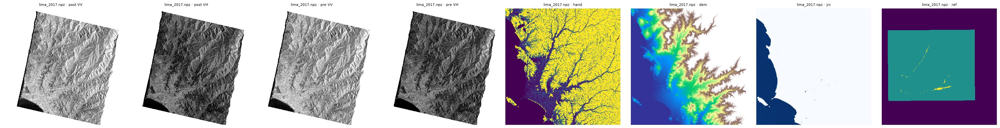

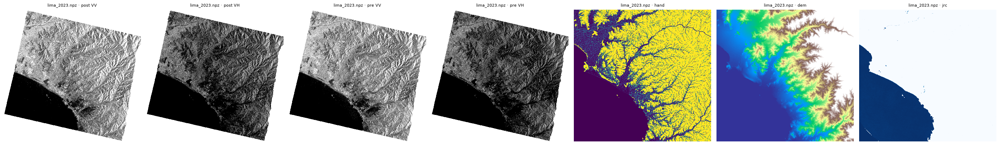

In [12]:
P.mostrar_escena(C.PRUEBAS / "lima_2017.npz", "lima_2017.npz")
P.mostrar_escena(C.PRUEBAS / "lima_2023.npz", "lima_2023.npz")

## 5. ¿Sirve cada evento para entrenar detección de agua?
Indicadores medidos sobre la muestra de la sección 2, con las **etiquetas originales**:

| columna | qué mide |
|---|---|
| `agua_permanente_pct` | % del agua permanente JRC (ocurrencia ≥ 80 %) que la etiqueta marca como agua |
| `agua_oscura_pct` | % del agua etiquetada con VH < −18 dB (agua visible en radar) |
| `mancha_mediana_m2`, `area_manchas_lt_1ha_pct`, `area_cuerpos_gt_100ha_pct` | tamaño de las manchas de agua etiquetadas: lo que interesa para Lima son las chicas (< 1 ha) |
| `auc_vh` | qué tan bien separa VH el agua del resto (bajo = hay “tierra oscura”, no necesariamente mala etiqueta) |
| `tierra_oscura_pct` | % de píxeles sin agua con VH < −20 dB: ejemplos negativos difíciles, como el desierto de Lima |
| `similitud_lima` | intersección del histograma de VH sin agua con el de la tierra de Lima Sur 2023 (1 = igual) |
| `auc_dvh` | qué tan bien separa ΔVH la inundación del resto (solo con imagen previa) |

In [13]:
ruta_cal = C.PREPARADO / "calidad.csv"
if ruta_cal.exists() and not REHACER and set(pd.read_csv(ruta_cal).evento) == set(items.evento):
    cal = pd.read_csv(ruta_cal)
else:
    cal = P.evaluar_calidad(muestra, items, P.vh_tierra_lima())
    cal.to_csv(ruta_cal, index=False)
pd.set_option("display.max_colwidth", 80)
cal[["dataset", "evento", "particion", "origen", "items", "items_muestra", "ventanas", "agua_permanente_pct", "agua_oscura_pct", "manchas", "mancha_mediana_m2", "area_manchas_lt_1ha_pct", "area_cuerpos_gt_100ha_pct", "auc_vh",
     "tierra_oscura_pct", "similitud_lima", "auc_dvh", "sirve_agua", "motivo_agua", "sirve_cambio", "motivo_cambio"]].round(3)

,dataset,evento,particion,origen,items,items_muestra,ventanas,agua_permanente_pct,agua_oscura_pct,manchas,...,area_manchas_lt_1ha_pct,area_cuerpos_gt_100ha_pct,auc_vh,tierra_oscura_pct,similitud_lima,auc_dvh,sirve_agua,motivo_agua,sirve_cambio,motivo_cambio
0,kurosiwo,chad,train,manual,32,32,32,98.511,94.201,186,...,2.088,30.487,0.982,3.355,0.369,0.890,True,sirve,True,sirve
1,kurosiwo,harvey,train+val,manual,4309,40,4309,NaN,96.492,262,...,4.439,0.000,0.990,1.357,0.339,0.970,True,sirve,True,sirve
2,kurosiwo,yibuti,train,manual,19,19,19,63.841,95.241,45,...,4.727,0.000,0.911,27.965,0.696,0.652,True,sirve,False,la inundación no se separa por ΔVH (AUC 0.65)


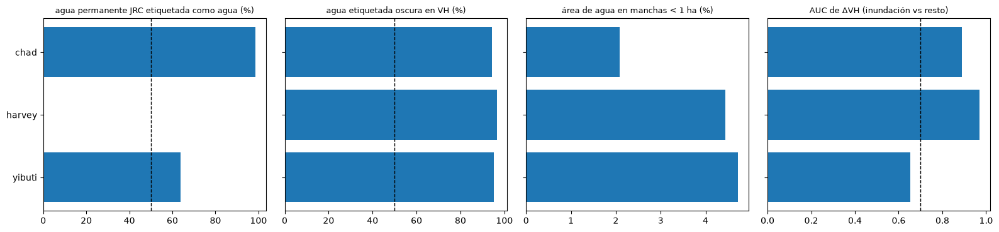

In [14]:
q = C.CALIDAD
orden = cal.sort_values("evento").reset_index(drop=True)
y = np.arange(len(orden))
paneles = [("agua_permanente_pct", q["agua_permanente_min"], "agua permanente JRC etiquetada como agua (%)"),
           ("agua_oscura_pct", q["agua_oscura_min"], "agua etiquetada oscura en VH (%)"),
           ("area_manchas_lt_1ha_pct", None, "área de agua en manchas < 1 ha (%)"),
           ("auc_dvh", q["auc_dvh_min"], "AUC de ΔVH (inundación vs resto)")]
fig, ejes = plt.subplots(1, len(paneles), figsize=(16, 2 + 0.6 * len(orden)), sharey=True)
for ax, (col, lim, titulo) in zip(ejes, paneles):
    ax.barh(y, orden[col].fillna(0), color="#1f77b4")
    if lim is not None:
        ax.axvline(lim, color="k", ls="--", lw=1)
    ax.set_title(titulo, fontsize=9)
ejes[0].set_yticks(y, orden.evento)
ejes[0].invert_yaxis()
plt.tight_layout()

### 5.1 Resumen por fuente

In [15]:
cal.groupby("dataset").agg(eventos=("evento", "size"), sirven_agua=("sirve_agua", "sum"), sirven_cambio=("sirve_cambio", "sum"),
                           agua_permanente_pct=("agua_permanente_pct", "mean"), agua_oscura_pct=("agua_oscura_pct", "mean")).round(1)

,eventos,sirven_agua,sirven_cambio,agua_permanente_pct,agua_oscura_pct
dataset,,,,,
kurosiwo,3,3,2,81.2,95.3


## 6. Inventario de ventanas (muestra de los eventos que sirven)
De cada evento que pasó la evaluación se toman items al azar hasta tener unas `VENTANAS_INVENTARIO` ventanas. Se recorren solo sus etiquetas para conocer la fracción válida y de agua de cada ventana de 256×256.

In [16]:
ruta_inv = C.PREPARADO / "inventario.csv"
vigente = lambda df: "item" in df and df.groupby("item").particion.first().to_dict().items() <= items.set_index("item").particion.to_dict().items()
if ruta_inv.exists() and not REHACER and vigente(pd.read_csv(ruta_inv)):   # se rehace si cambiaron los items o la partición
    inv = pd.read_csv(ruta_inv)
else:
    muestra_inv = P.muestra_inventario(items, cal)
    bajar_teselas(muestra_inv)
    inv = D.inventario(muestra_inv)
    inv.to_csv(ruta_inv, index=False)
inv.groupby(["dataset", "evento"]).agg(items=("item", "nunique"), ventanas=("i", "size"),
                                       agua_media=("frac_agua", "mean")).join(
    items.groupby("evento").size().rename("items_total"), on="evento").round(3)

items  ventanas  agua_media  items_total
dataset  evento                                          
kurosiwo chad       32        32       0.096           32
         harvey   4309      4309       0.086         4309
         yibuti     19        19       0.028           19

## 7. Selección y extracción de parches
Tope de `MAX_PARCHES_EVENTO` parches por evento con `FRAC_CON_AGUA` de parches con agua. Cada `.npz` guarda `img` (VV_pre, VH_pre, VV_post, VH_post en dB, float16), `lab` (0 sin agua, 1 permanente, 2 inundación abierta, 3 urbana), `val` y `val_pre`. Las columnas `agua` y `cambio` del índice dicen en qué modo se usa cada parche.

In [17]:
ruta_idx = C.PREPARADO / "indice.csv"
if ruta_idx.exists() and not REHACER and vigente(pd.read_csv(ruta_idx)):
    indice = pd.read_csv(ruta_idx)
else:
    seleccion = D.muestrear(inv)
    indice = P.marcar_modos(D.extraer_parches(seleccion), cal)
    indice.to_csv(ruta_idx, index=False)
pd.concat({m: indice[indice[m]].groupby(["particion", "dataset"]).agg(parches=("ruta", "size"),
                                                                     con_agua=("frac_agua", lambda x: (x > C.FRAC_AGUA_POSITIVO).sum()))
           for m in C.MODOS}, axis=1).fillna(0).astype(int)

parches:   0%|          | 0/4360 [00:00<?, ?it/s]

agua           cambio         
                   parches con_agua parches con_agua
particion dataset                                   
train     kurosiwo    3349     2115    3330     2108
val       kurosiwo    1011      687    1011      687

## 8. Partición y estadísticas de normalización (solo Train)

In [18]:
# Harvey está en train y val (bloques geográficos): lo que no se puede repetir es una tesela.
particion = {k: g.groupby("evento").item.nunique().to_dict() for k, g in indice.groupby("particion")}
json.dump(particion, open(C.PREPARADO / "particion.json", "w"), indent=2)
assert not set(indice[indice.particion == "train"].item) & set(indice[indice.particion == "val"].item), "una tesela aparece en train y val"
print("teselas por partición y evento:", particion)

ruta_stats = C.PREPARADO / "stats.json"
if ruta_stats.exists() and not REHACER:
    stats = json.load(open(ruta_stats))
else:
    stats = D.estadisticas(indice)
    json.dump(stats, open(ruta_stats, "w"), indent=2)
pd.DataFrame(stats).set_index("canales").round(3)

teselas por partición y evento: {'train': {'chad': 32, 'harvey': 3298, 'yibuti': 19}, 'val': {'harvey': 1011}}


estadísticas: 0it [00:00, ?it/s]

,media,std,pixeles
canales,,,
VV_pre,-10.794,2.589,164285239.0
VH_pre,-16.438,2.766,164285239.0
VV_post,-9.536,2.597,164287111.0
VH_post,-15.041,3.251,164287111.0


## 9. Empaquetado para la GPU
Los `.npz` se copian una vez a arreglos `.npy` sin comprimir, que el entrenamiento lee directamente.

In [19]:
carpeta, posiciones = E.empaquetar(indice)
print(f"{len(posiciones)} parches en {carpeta}")

empaquetando:   0%|          | 0/4360 [00:00<?, ?it/s]

4360 parches en C:\Ciclo09\MachineLearning\ProyectoMachineLearning\Data\procesado\preparado\empaquetado


## 10. Visualización de parches
Dos parches al azar con agua de cada evento y partición, tal como quedan guardados para el entrenamiento.

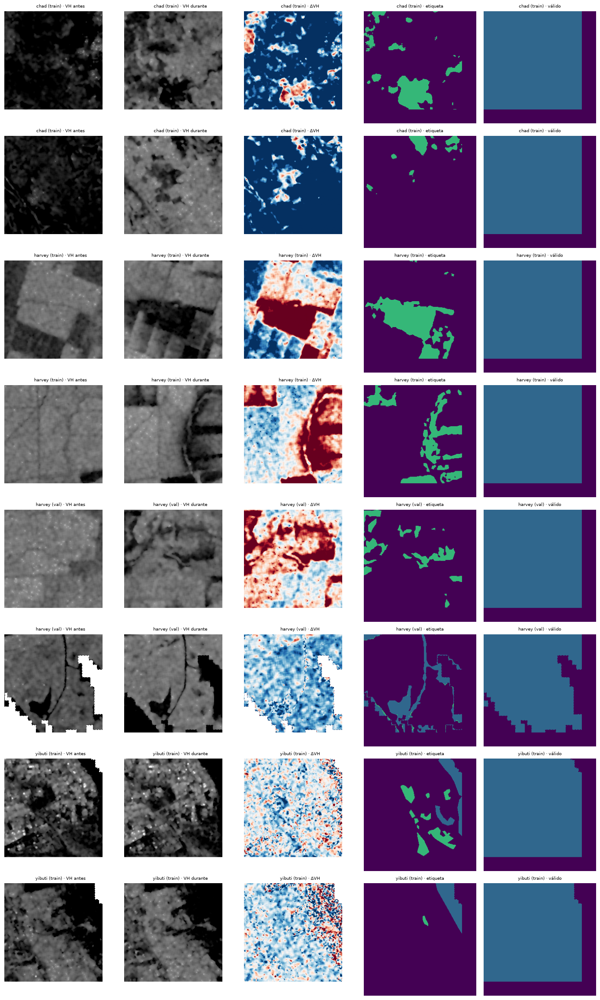

In [20]:
ejemplos = indice[indice.frac_agua > 0.05].sample(frac=1, random_state=C.SEMILLA).groupby(["evento", "particion"]).head(2)
ejemplos = ejemplos.sort_values(["evento", "particion"])
fig, ejes = plt.subplots(len(ejemplos), 5, figsize=(14, 2.9 * len(ejemplos)))
for fila, e in zip(np.atleast_2d(ejes), ejemplos.itertuples()):
    d = np.load(e.ruta)
    img = d["img"].astype("float32")
    for ax, x, t in zip(fila, [img[1], img[3], img[3] - img[1], d["lab"], d["val"]],
                        ["VH antes", "VH durante", "ΔVH", "etiqueta", "válido"]):
        cm, lo, hi = ("gray", -25, 0) if t.startswith("VH") else ("RdBu", -6, 6) if t == "ΔVH" else ("viridis", 0, 3)
        ax.imshow(x, cmap=cm, vmin=lo, vmax=hi)
        ax.set_title(f"{e.evento} ({e.particion}) · {t}", fontsize=7)
        ax.axis("off")
plt.tight_layout()

## 11. Datos crudos que no sirven
Eventos que no pasan los criterios en ningún modo. Sus archivos crudos se pueden borrar: no entran en `preparado/`.

In [ ]:
no_sirven = cal[~cal.sirve_agua & ~cal.sirve_cambio]
filas = []
for f in no_sirven.itertuples():
    rutas = items[items.evento == f.evento].item
    mb = sum(sum(p.stat().st_size for p in Path(r).iterdir()) if Path(r).is_dir() else Path(r).stat().st_size for r in rutas) / 1e6
    filas.append({"dataset": f.dataset, "evento": f.evento, "items": len(rutas), "MB": round(mb), "motivo": f.motivo_agua})
pd.DataFrame(filas, columns=["dataset", "evento", "items", "MB", "motivo"])